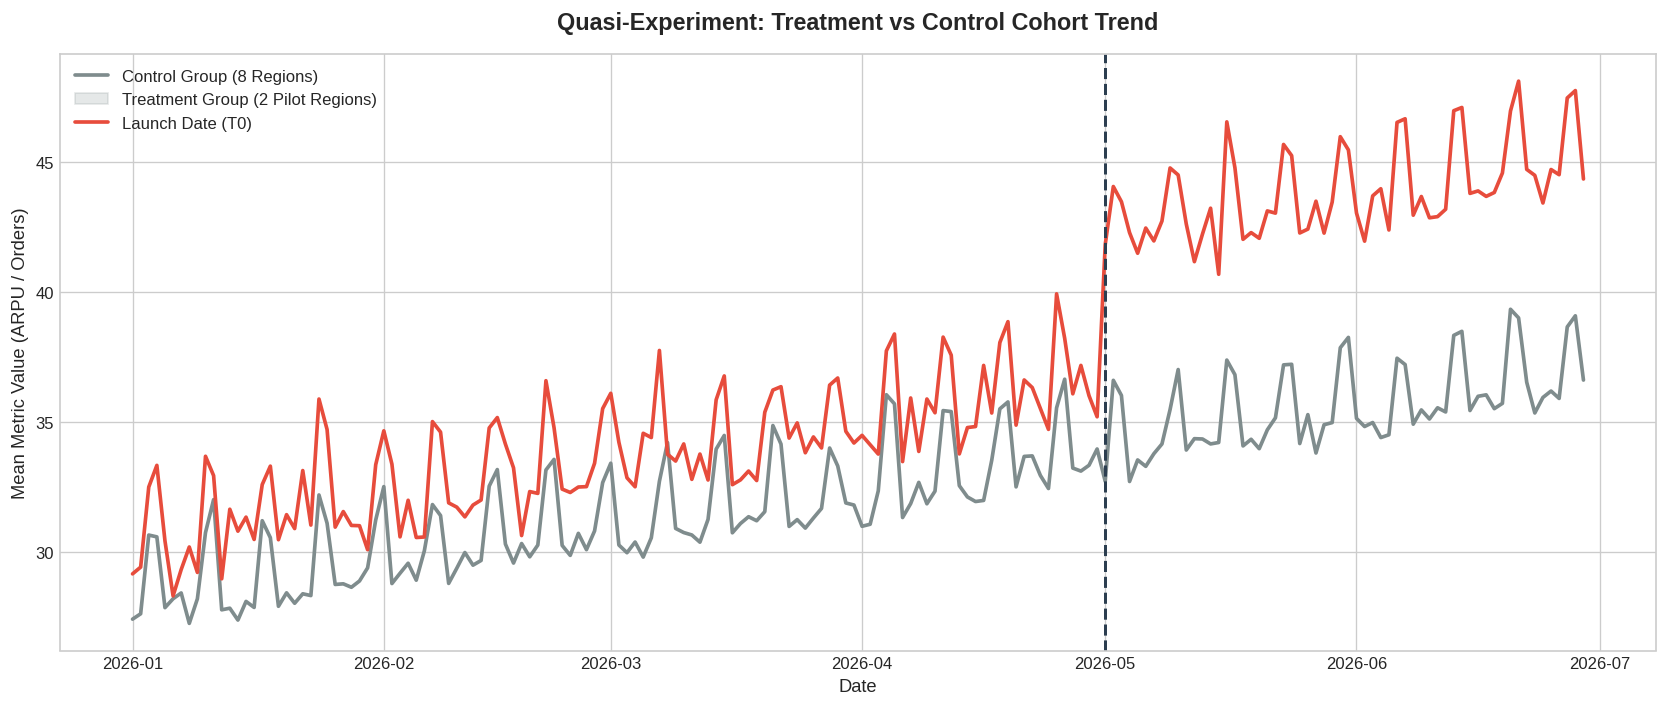

,date,day_index,region,is_treatment_group,is_post_period,metric_value
0,2026-01-01,0,Region_1,1,0,25.05
1,2026-01-02,1,Region_1,1,0,26.32
2,2026-01-03,2,Region_1,1,0,28.16
3,2026-01-04,3,Region_1,1,0,28.21
4,2026-01-05,4,Region_1,1,0,26.11


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

n_days = 180
intervention_day = 120
regions = [f"Region_{i}" for i in range(1, 11)]
treatment_regions = ["Region_1", "Region_2"]
true_causal_lift = 5.5

dates = pd.date_range(start="2026-01-01", periods=n_days, freq="D")

records = []
region_baselines = {r: np.random.uniform(20, 35) for r in regions}

for r in regions:
    is_treatment = 1 if r in treatment_regions else 0
    base = region_baselines[r]

    for t_idx, d in enumerate(dates):
        trend = 0.05 * t_idx
        day_of_week = d.weekday()
        weekend_effect = 3.0 if day_of_week in [5, 6] else 0.0

        is_post = 1 if t_idx >= intervention_day else 0
        shock = true_causal_lift if (is_treatment == 1 and is_post == 1) else 0.0

        noise = np.random.normal(0, 1.2)
        metric_value = base + trend + weekend_effect + shock + noise

        records.append({
            "date": d,
            "day_index": t_idx,
            "region": r,
            "is_treatment_group": is_treatment,
            "is_post_period": is_post,
            "metric_value": round(metric_value, 2)
        })

df_panel = pd.DataFrame(records)
df_panel.to_csv("synthetic_product_panel.csv", index=False)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(14, 6), dpi=120)

avg_trend = df_panel.groupby(["date", "is_treatment_group"])["metric_value"].mean().reset_index()

sns.lineplot(
    data=avg_trend,
    x="date",
    y="metric_value",
    hue="is_treatment_group",
    palette={0: "#7f8c8d", 1: "#e74c3c"},
    linewidth=2.2,
    ax=ax
)

intervention_date = dates[intervention_day]
ax.axvline(intervention_date, color="#2c3e50", linestyle="--", linewidth=1.8)

ax.set_title("Quasi-Experiment: Treatment vs Control Cohort Trend", fontsize=14, weight="bold", pad=15)
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Mean Metric Value (ARPU / Orders)", fontsize=11)
ax.legend(title="", labels=["Control Group (8 Regions)", "Treatment Group (2 Pilot Regions)", "Launch Date (T0)"])

plt.tight_layout()
plt.savefig("treatment_vs_control_trend.png")
plt.show()

df_panel.head()

In [2]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

df_panel["did_interaction"] = df_panel["is_treatment_group"] * df_panel["is_post_period"]

model_did = smf.ols(
    formula="metric_value ~ is_treatment_group + is_post_period + did_interaction",
    data=df_panel
).fit(cov_type="cluster", cov_kwds={"groups": df_panel["region"]})

print(model_did.summary())

pre_period_df = df_panel[df_panel["is_post_period"] == 0].copy()
pre_period_df["time_interaction"] = pre_period_df["day_index"] * pre_period_df["is_treatment_group"]

parallel_trend_model = smf.ols(
    formula="metric_value ~ day_index + is_treatment_group + time_interaction",
    data=pre_period_df
).fit(cov_type="cluster", cov_kwds={"groups": pre_period_df["region"]})

print("\n--- PARALEL TREND TESTİ SONUCU ---")
print(f"Time Interaction p-value: {parallel_trend_model.pvalues['time_interaction']:.4f}")

                            OLS Regression Results                            
Dep. Variable:           metric_value   R-squared:                       0.318
Model:                            OLS   Adj. R-squared:                  0.317
Method:                 Least Squares   F-statistic:                 4.996e+04
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           2.60e-19
Time:                        11:04:41   Log-Likelihood:                -5424.0
No. Observations:                1800   AIC:                         1.086e+04
Df Residuals:                    1796   BIC:                         1.088e+04
Df Model:                           3                                         
Covariance Type:              cluster                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             31.1871      1

In [ ]:
event_window_before = 20
event_window_after = 20

df_event = df_panel[
    (df_panel["day_index"] >= intervention_day - event_window_before) &
    (df_panel["day_index"] <= intervention_day + event_window_after)
].copy()

df_event["rel_day"] = df_event["day_index"] - intervention_day

lead_lag_dummies = pd.get_dummies(df_event["rel_day"], prefix="d", drop_first=False, dtype=int)
for col in lead_lag_dummies.columns:
    df_event[f"treat_{col}"] = lead_lag_dummies[col] * df_event["is_treatment_group"]

treat_cols = [c for c in df_event.columns if c.startswith("treat_d_") and c != "treat_d_-1"]
formula_event = "metric_value ~ C(region) + C(date) + " + " + ".join(treat_cols)

model_event = smf.ols(formula=formula_event, data=df_event).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_event["region"]}
)

coef_data = []
for day in range(-event_window_before, event_window_after + 1):
    col_name = f"treat_d_{day}"
    if day == -1:
        coef_data.append({"rel_day": day, "coef": 0.0, "ci_lower": 0.0, "ci_upper": 0.0})
    elif col_name in model_event.params:
        c = model_event.params[col_name]
        se = model_event.bse[col_name]
        coef_data.append({
            "rel_day": day,
            "coef": c,
            "ci_lower": c - 1.96 * se,
            "ci_upper": c + 1.96 * se
        })

df_event_plot = pd.DataFrame(coef_data)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(13, 5), dpi=120)

ax.errorbar(
    df_event_plot["rel_day"],
    df_event_plot["coef"],
    yerr=[
        df_event_plot["coef"] - df_event_plot["ci_lower"],
        df_event_plot["ci_upper"] - df_event_plot["coef"]
    ],
    fmt="o",
    color="#2980b9",
    ecolor="#bdc3c7",
    elinewidth=1.8,
    capsize=3,
    markersize=5
)

ax.axhline(0, color="#7f8c8d", linestyle="--", linewidth=1.2)
ax.axvline(-0.5, color="#c0392b", linestyle=":", linewidth=1.5)

ax.set_title("Event Study: Dynamic Treatment Effects Across Leads and Lags", fontsize=13, weight="bold", pad=12)
ax.set_xlabel("Days Relative to Intervention (t = 0)", fontsize=11)
ax.set_ylabel("Estimated Causal Effect (Lift)", fontsize=11)

plt.tight_layout()
plt.savefig("event_study_plot.png")
plt.show()


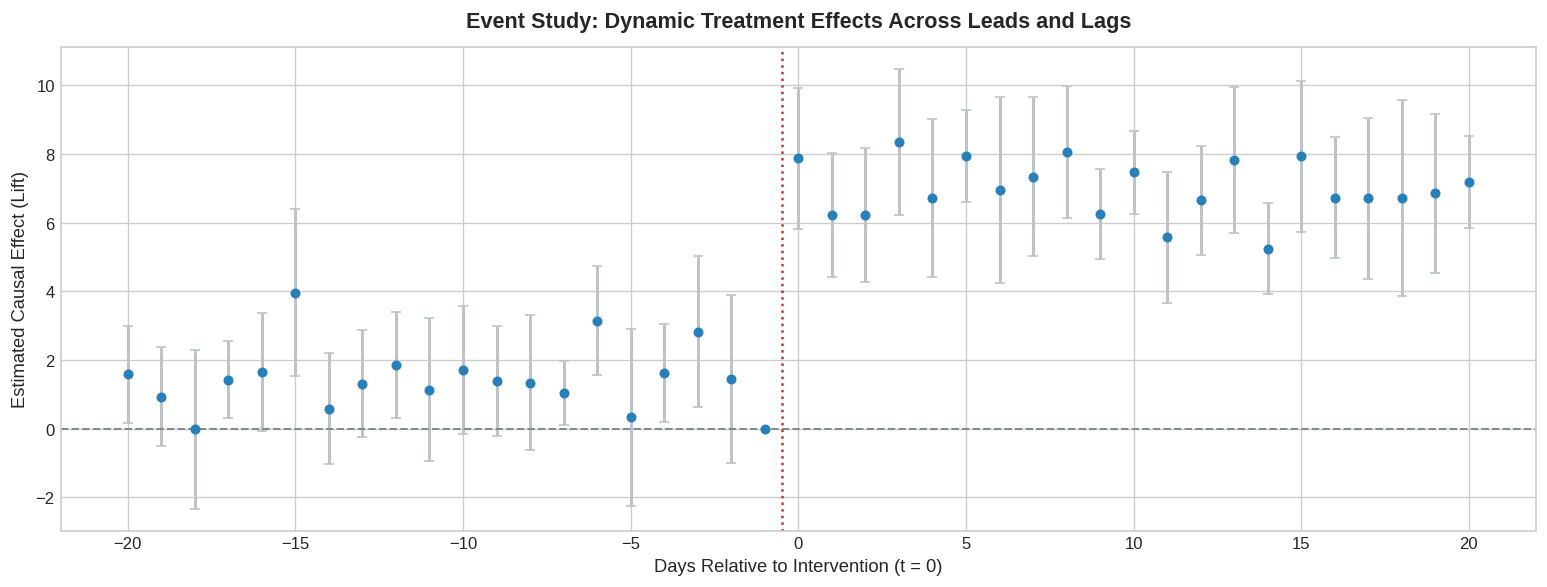

In [4]:
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

event_window_before = 20
event_window_after = 20

df_event = df_panel[
    (df_panel["day_index"] >= intervention_day - event_window_before) &
    (df_panel["day_index"] <= intervention_day + event_window_after)
].copy()

df_event["rel_day"] = df_event["day_index"] - intervention_day

for d in range(-event_window_before, event_window_after + 1):
    tag = f"m{abs(d)}" if d < 0 else f"p{d}"
    df_event[f"lead_lag_{tag}"] = ((df_event["rel_day"] == d) & (df_event["is_treatment_group"] == 1)).astype(int)

treat_cols = [f"lead_lag_{'m' + str(abs(d)) if d < 0 else 'p' + str(d)}" for d in range(-event_window_before, event_window_after + 1) if d != -1]
formula_event = "metric_value ~ C(region) + C(date) + " + " + ".join(treat_cols)

model_event = smf.ols(formula=formula_event, data=df_event).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_event["region"]}
)

coef_data = []
for d in range(-event_window_before, event_window_after + 1):
    tag = f"m{abs(d)}" if d < 0 else f"p{d}"
    col_name = f"lead_lag_{tag}"
    if d == -1:
        coef_data.append({"rel_day": d, "coef": 0.0, "ci_lower": 0.0, "ci_upper": 0.0})
    elif col_name in model_event.params:
        c = model_event.params[col_name]
        se = model_event.bse[col_name]
        coef_data.append({
            "rel_day": d,
            "coef": c,
            "ci_lower": c - 1.96 * se,
            "ci_upper": c + 1.96 * se
        })

df_event_plot = pd.DataFrame(coef_data)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(13, 5), dpi=120)

ax.errorbar(
    df_event_plot["rel_day"],
    df_event_plot["coef"],
    yerr=[
        df_event_plot["coef"] - df_event_plot["ci_lower"],
        df_event_plot["ci_upper"] - df_event_plot["coef"]
    ],
    fmt="o",
    color="#2980b9",
    ecolor="#bdc3c7",
    elinewidth=1.8,
    capsize=3,
    markersize=5
)

ax.axhline(0, color="#7f8c8d", linestyle="--", linewidth=1.2)
ax.axvline(-0.5, color="#c0392b", linestyle=":", linewidth=1.5)

ax.set_title("Event Study: Dynamic Treatment Effects Across Leads and Lags", fontsize=13, weight="bold", pad=12)
ax.set_xlabel("Days Relative to Intervention (t = 0)", fontsize=11)
ax.set_ylabel("Estimated Causal Effect (Lift)", fontsize=11)

plt.tight_layout()
plt.savefig("event_study_plot.png")
plt.show()

Average Daily Lift: 5.74
Cumulative Incremental Orders/ARPU: 344.13
Relative Causal Effect: %15.05


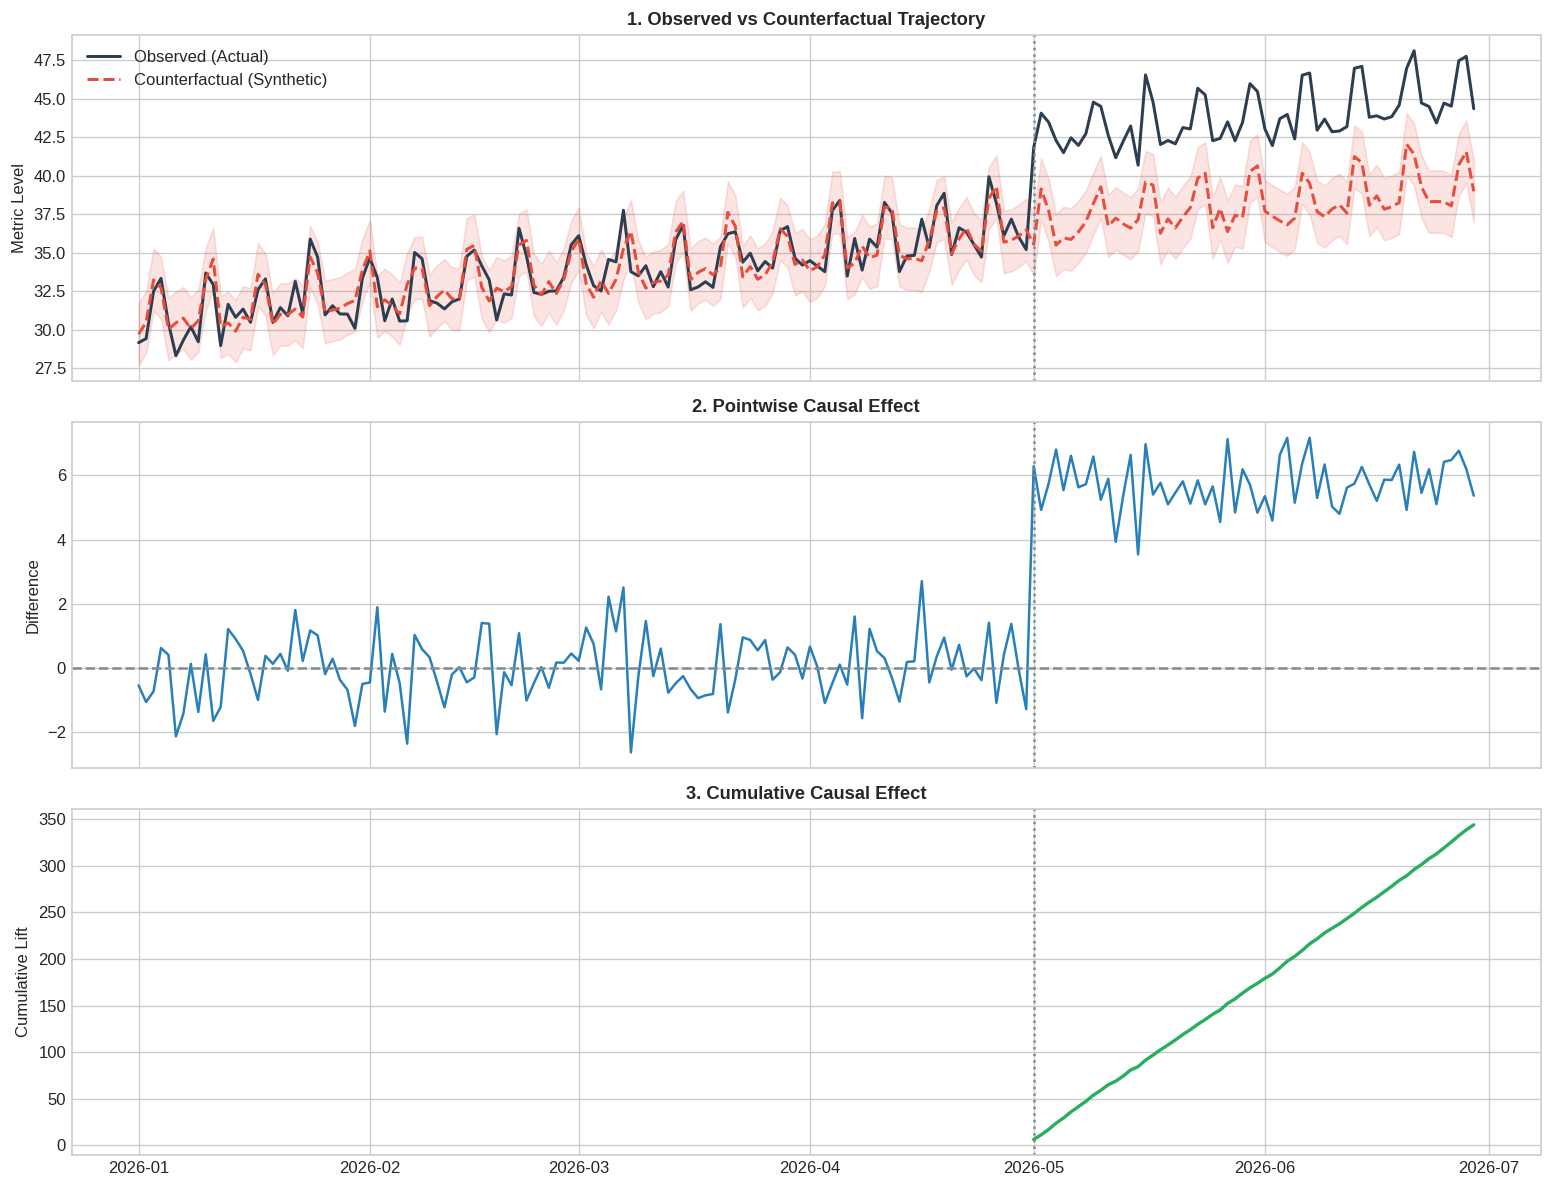

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

pivot_df = df_panel.pivot(index="date", columns="region", values="metric_value")

treat_series = pivot_df[["Region_1", "Region_2"]].mean(axis=1)
control_df = pivot_df[[r for r in pivot_df.columns if r not in ["Region_1", "Region_2"]]]

pre_mask = pivot_df.index < dates[intervention_day]
post_mask = pivot_df.index >= dates[intervention_day]

X_pre = sm.add_constant(control_df[pre_mask])
y_pre = treat_series[pre_mask]

synthetic_model = sm.OLS(y_pre, X_pre).fit()

X_all = sm.add_constant(control_df)
counterfactual = synthetic_model.predict(X_all)

pred_se = np.sqrt(synthetic_model.scale)
ci_lower = counterfactual - 1.96 * pred_se
ci_upper = counterfactual + 1.96 * pred_se

point_effect = treat_series - counterfactual
point_effect_post = point_effect[post_mask]

abs_lift_mean = point_effect_post.mean()
cum_lift_total = point_effect_post.sum()
rel_lift_pct = (point_effect_post / counterfactual[post_mask]).mean() * 100

print(f"Average Daily Lift: {abs_lift_mean:.2f}")
print(f"Cumulative Incremental Orders/ARPU: {cum_lift_total:.2f}")
print(f"Relative Causal Effect: %{rel_lift_pct:.2f}")

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(13, 10), dpi=120, sharex=True)

axes[0].plot(pivot_df.index, treat_series, color="#2c3e50", label="Observed (Actual)", linewidth=1.8)
axes[0].plot(pivot_df.index, counterfactual, color="#e74c3c", linestyle="--", label="Counterfactual (Synthetic)", linewidth=1.8)
axes[0].fill_between(pivot_df.index, ci_lower, ci_upper, color="#e74c3c", alpha=0.15)
axes[0].axvline(dates[intervention_day], color="#7f8c8d", linestyle=":")
axes[0].set_ylabel("Metric Level", fontsize=10)
axes[0].set_title("1. Observed vs Counterfactual Trajectory", fontsize=11, weight="bold")
axes[0].legend(loc="upper left")

axes[1].plot(pivot_df.index, point_effect, color="#2980b9", linewidth=1.5)
axes[1].axhline(0, color="#7f8c8d", linestyle="--")
axes[1].axvline(dates[intervention_day], color="#7f8c8d", linestyle=":")
axes[1].set_ylabel("Difference", fontsize=10)
axes[1].set_title("2. Pointwise Causal Effect", fontsize=11, weight="bold")

axes[2].plot(pivot_df.index[post_mask], point_effect_post.cumsum(), color="#27ae60", linewidth=2.0)
axes[2].axvline(dates[intervention_day], color="#7f8c8d", linestyle=":")
axes[2].set_ylabel("Cumulative Lift", fontsize=10)
axes[2].set_title("3. Cumulative Causal Effect", fontsize=11, weight="bold")

plt.tight_layout()
plt.savefig("synthetic_control_counterfactual.png")
plt.show()